Hello

# Problem Statement:
Where and when do congestion-related electricity price impacts occur, and how do those impacts compare across locations?


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import seaborn as sns


In [ ]:

# Define file path
file_path = './data/Congestion_monthly_by_zone_2023_2025.csv'
if not os.path.exists(file_path):
    file_path = './data/Congestion_monthly_by_zone_2023_2025.csv'
# Load the dataset
congestion_dataframe = pd.read_csv(file_path)

# Display basic information
#print("Dataset Columns:", df.columns.tolist())
congestion_dataframe.head()




,year,month,season,zone,avg_lbmp,min_lbmp,max_lbmp,avg_congestion_cost,min_congestion_cost,max_congestion_cost
0,2023,1,Winter,A_west,30.744898,-286.00,2689.05,1.216413,-101.54,67.33
1,2023,1,Winter,B_genesee,32.829125,-310.17,2736.93,-0.620974,-83.89,51.04
2,2023,1,Winter,C_central,34.548231,-305.41,2815.56,-1.669340,-100.47,30.81
3,2023,1,Winter,D_north,31.572220,-401.79,2826.88,0.809649,-6.15,43.08
4,2023,1,Winter,E_mohawk_valley,34.900026,-316.32,2928.11,-1.081787,-168.11,10.81


In [ ]:
# Define file path
file_path = './data/Mosesouth_flow_2023_2025_raw.csv'
if not os.path.exists(file_path):
    file_path = './data/Mosesouth_flow_2023_2025_raw.csv'

# Load the dataset
mosesouth_dataframe = pd.read_csv(file_path)

# Display basic information
#print("Dataset Columns:", df.columns.tolist())
mosesouth_dataframe.head()

,formatted_timestamp,date,year,month,day,hour,Interface Name,avg_flow_mwh
0,2023-01-01T00:00,2023-01-01,2023,1,1,0,MOSES SOUTH,508.524167
1,2023-01-01T01:00,2023-01-01,2023,1,1,1,MOSES SOUTH,384.013333
2,2023-01-01T02:00,2023-01-01,2023,1,1,2,MOSES SOUTH,366.990000
3,2023-01-01T03:00,2023-01-01,2023,1,1,3,MOSES SOUTH,423.192500
4,2023-01-01T04:00,2023-01-01,2023,1,1,4,MOSES SOUTH,443.918333


## Clean the data

### STEP 1: Check for null


In [ ]:
print('Blank cells (congestion):', congestion_dataframe.isna().sum().sum())
print('Blank cells (Moses South):', mosesouth_dataframe.isna().sum().sum())
print('Duplicate zone-months:', congestion_dataframe.duplicated(['year', 'month', 'zone']).sum())
print('Duplicate flow hours:', mosesouth_dataframe['formatted_timestamp'].duplicated().sum())

print('\nMonths per zone (should all be 36):')
print(congestion_dataframe.groupby('zone').size())

Blank cells (congestion): 0
Blank cells (Moses South): 0
Duplicate zone-months: 0
Duplicate flow hours: 0

Months per zone (should all be 36):
zone
A_west             36
B_genesee          36
C_central          36
D_north            36
E_mohawk_valley    36
F_capital          36
G_hudson_valley    36
H_millwood         36
I_dunwoodie        36
J_new_york_city    36
K_long_island      36
dtype: int64


## Step 3 — Add a real date and readable zone labels
- `month_date` (first day of each month) lets us draw time-series charts in the right order.
- Labels like `J - New York City`, kept in A→K order (west to east).

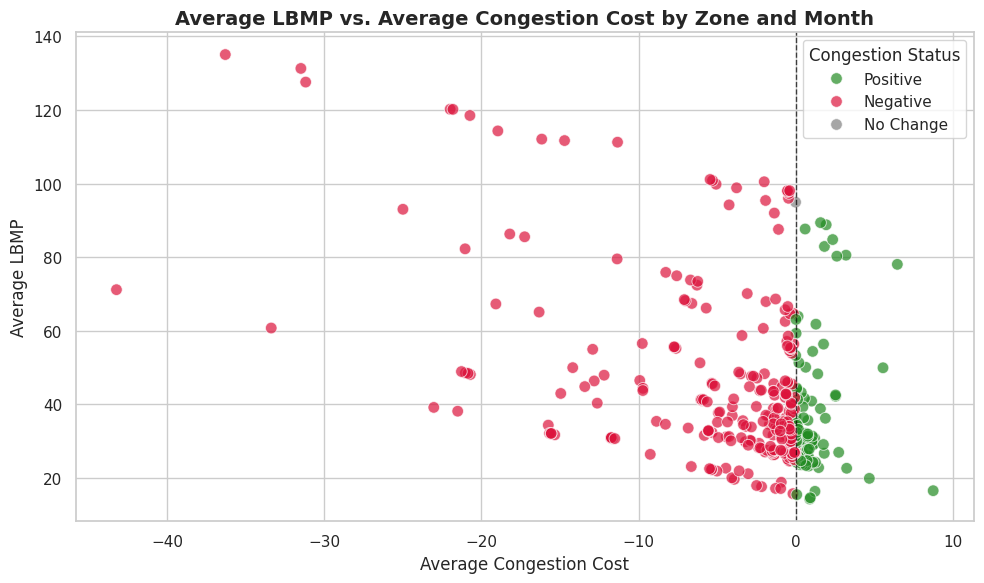

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# 2. Group by Zone and Month to calculate average LBMP and average Congestion Cost
grouped_df = (
    congestion_dataframe.groupby(['zone', 'year', 'month'])
    .agg({'avg_lbmp': 'mean', 'avg_congestion_cost': 'mean'})
    .reset_index()
)


# 3. Create the 'Congestion_Status' categorization column
def categorize_congestion(cc):
  if cc > 0:
    return 'Positive'
  elif cc < 0:
    return 'Negative'
  else:
    return 'No Change'


grouped_df['Congestion_Status'] = grouped_df['avg_congestion_cost'].apply(
    categorize_congestion
)

# 4. Plotting using Seaborn
plt.figure(figsize=(10, 6))

custom_palette = {'Positive': 'forestgreen', 'Negative': 'crimson', 'No Change': 'gray'}

sns.scatterplot(
    data=grouped_df,
    x='avg_congestion_cost',
    y='avg_lbmp',
    hue='Congestion_Status',
    palette=custom_palette,
    alpha=0.7,
    s=70,
)

plt.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
plt.title(
    'Average LBMP vs. Average Congestion Cost by Zone and Month',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Average Congestion Cost', fontsize=12)
plt.ylabel('Average LBMP', fontsize=12)
plt.legend(title='Congestion Status', loc='upper right', frameon=True)
plt.tight_layout()

# Save and show
plt.savefig('lbmp_vs_congestion_cost.png', dpi=300)
plt.show()

In [ ]:

# Define file path
file_path = './data/Congestion_monthly_by_zone_2023_2025.csv'
if not os.path.exists(file_path):
    file_path = './data/Congestion_monthly_by_zone_2023_2025.csv'
# Load the dataset
congestion_dataframe = pd.read_csv(file_path)

# Display basic information
#print("Dataset Columns:", df.columns.tolist())
congestion_dataframe.head()

,year,month,season,zone,avg_lbmp,min_lbmp,max_lbmp,avg_congestion_cost,min_congestion_cost,max_congestion_cost
0,2023,1,Winter,A_west,30.744898,-286.00,2689.05,1.216413,-101.54,67.33
1,2023,1,Winter,B_genesee,32.829125,-310.17,2736.93,-0.620974,-83.89,51.04
2,2023,1,Winter,C_central,34.548231,-305.41,2815.56,-1.669340,-100.47,30.81
3,2023,1,Winter,D_north,31.572220,-401.79,2826.88,0.809649,-6.15,43.08
4,2023,1,Winter,E_mohawk_valley,34.900026,-316.32,2928.11,-1.081787,-168.11,10.81


Correlation Analysis:
- Pearson Correlation (linear): -0.4511
- Spearman Rank Correlation (monotonic): -0.3206


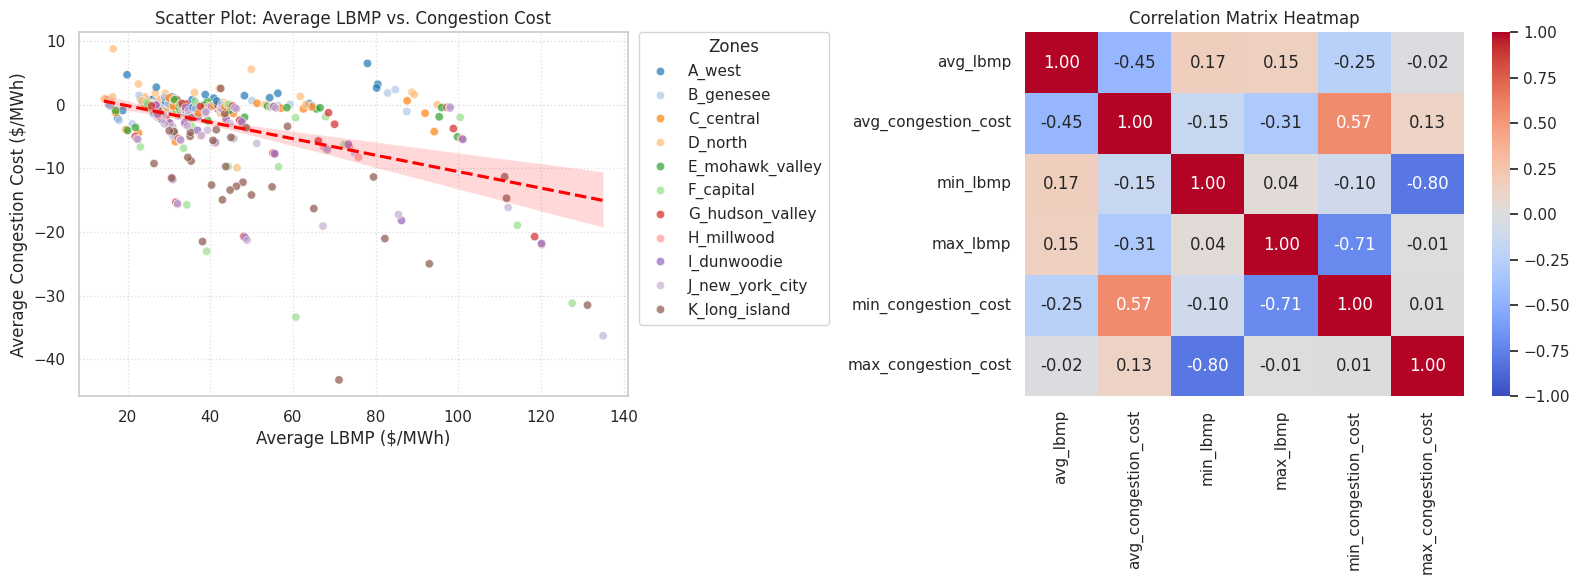

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Compute different correlation coefficients
pearson_corr = congestion_dataframe['avg_lbmp'].corr(congestion_dataframe['avg_congestion_cost'], method='pearson')
spearman_corr = congestion_dataframe['avg_lbmp'].corr(congestion_dataframe['avg_congestion_cost'], method='spearman')

print(f"Correlation Analysis:")
print(f"- Pearson Correlation (linear): {pearson_corr:.4f}")
print(f"- Spearman Rank Correlation (monotonic): {spearman_corr:.4f}")

# Create the visualization layout
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter plot with a linear regression line
sns.scatterplot(
    ax=axes[0],
    data=congestion_dataframe,
    x='avg_lbmp',
    y='avg_congestion_cost',
    hue='zone',
    alpha=0.7,
    palette='tab20'
)
sns.regplot(
    ax=axes[0],
    data=congestion_dataframe,
    x='avg_lbmp',
    y='avg_congestion_cost',
    scatter=False,
    color='red',
    line_kws={'label': f'Trendline (r={pearson_corr:.2f})', 'linestyle': '--'}
)
axes[0].set_title('Scatter Plot: Average LBMP vs. Congestion Cost', fontsize=12)
axes[0].set_xlabel('Average LBMP ($/MWh)')
axes[0].set_ylabel('Average Congestion Cost ($/MWh)')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title='Zones')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Correlation Heatmap
corr_matrix = congestion_dataframe[['avg_lbmp', 'avg_congestion_cost', 'min_lbmp', 'max_lbmp', 'min_congestion_cost', 'max_congestion_cost']].corr()
sns.heatmap(
    ax=axes[1],
    data=corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
axes[1].set_title('Correlation Matrix Heatmap', fontsize=12)

plt.tight_layout()
plt.show()

Top 3 zones with the highest average congestion costs:
zone
D_north      0.853382
A_west       0.790516
B_genesee   -0.079729
Name: avg_congestion_cost, dtype: float64


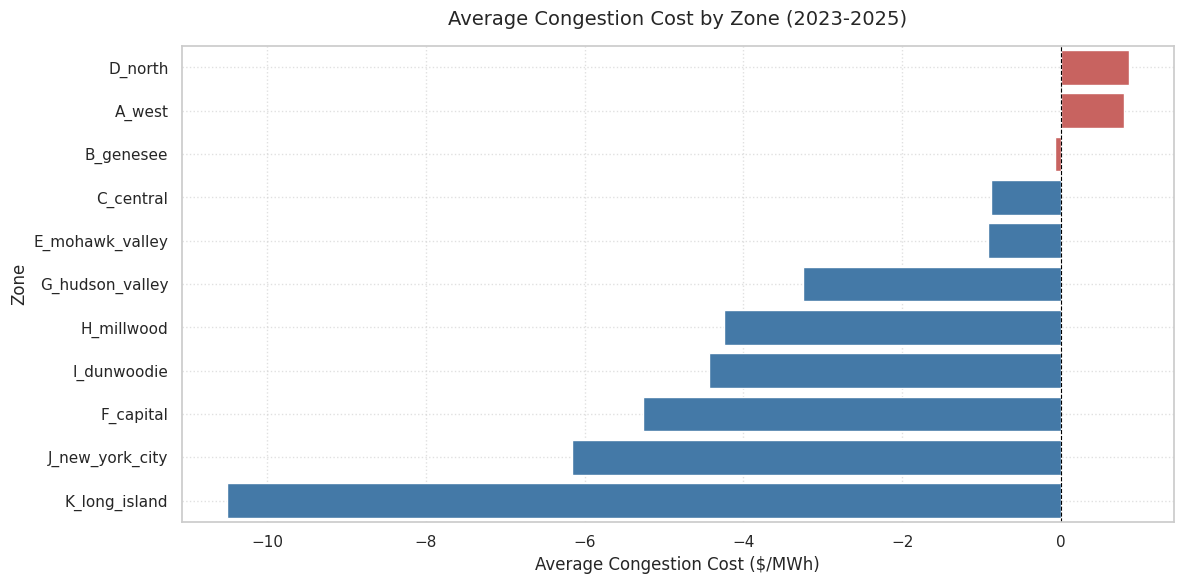

In [ ]:
# Calculate the average congestion cost for each zone
top_congestion_zones = congestion_dataframe.groupby('zone')['avg_congestion_cost'].mean().sort_values(ascending=False)

print("Top 3 zones with the highest average congestion costs:")
print(top_congestion_zones.head(3))

# Create a bar chart showing the average congestion cost for all zones, highlighting the top 3
plt.figure(figsize=(12, 6))
colors = ['#d9534f' if zone in top_congestion_zones.head(3).index else '#337ab7' for zone in top_congestion_zones.index]

sns.barplot(
    x=top_congestion_zones.values,
    y=top_congestion_zones.index,
    palette=colors,
    hue=top_congestion_zones.index,
    legend=False
)

plt.title('Average Congestion Cost by Zone (2023-2025)', fontsize=14, pad=15)
plt.xlabel('Average Congestion Cost ($/MWh)', fontsize=12)
plt.ylabel('Zone', fontsize=12)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate the average LBMP for each zone
avg_lbmp_by_zone = congestion_dataframe.groupby('zone')['avg_lbmp'].mean().sort_values(ascending=False)

print("Average LBMP by Zone (2023-2025):")
display(avg_lbmp_by_zone.to_frame(name='Average LBMP ($/MWh)'))

Average LBMP by Zone (2023-2025):


,Average LBMP ($/MWh)
zone,
K_long_island,51.703814
J_new_york_city,47.121638
F_capital,45.312341
I_dunwoodie,45.236490
H_millwood,44.904779
G_hudson_valley,43.748422
E_mohawk_valley,40.466515
C_central,39.058037
D_north,37.606914


Top 3 zones by Average LBMP:
zone
K_long_island      51.703814
J_new_york_city    47.121638
F_capital          45.312341
Name: avg_lbmp, dtype: float64


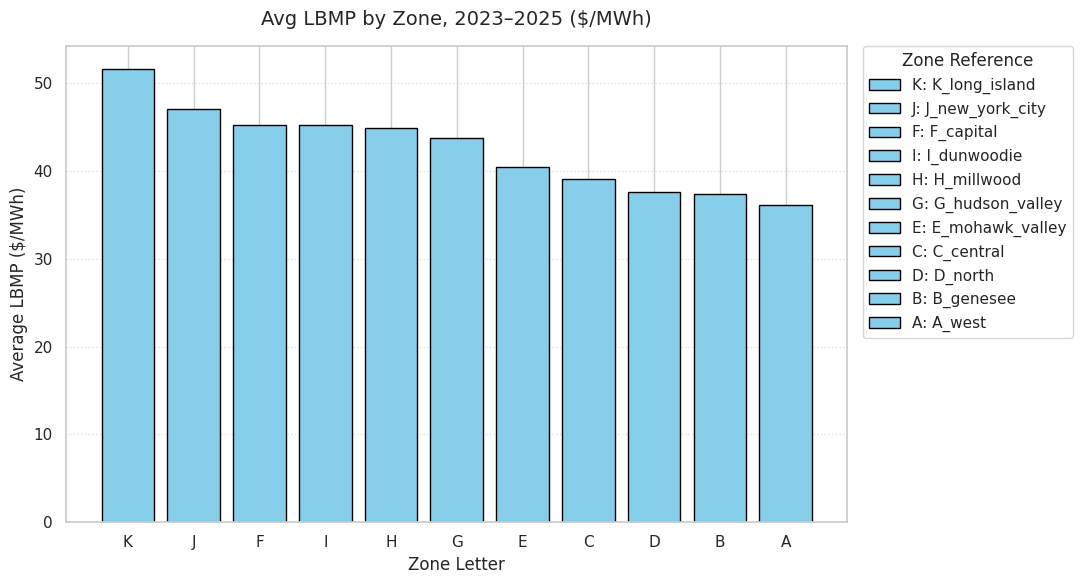

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Correct path inside /content/data/
testing_data = pd.read_csv("./data/Congestion_monthly_by_zone_2023_2025.csv")

avg = testing_data.groupby("zone")["avg_lbmp"].mean().sort_values(ascending=False)
print("Top 3 zones by Average LBMP:")
print(avg.head(3))

# Extract just the first letter (zone letter) from the index labels
zone_letters = [zone.split('_')[0] for zone in avg.index]

# Create a clean bar plot with only the zone letters on the X-axis
plt.figure(figsize=(11, 6))
bars = plt.bar(zone_letters, avg.values, color="skyblue", edgecolor="black")

# Create legend entries mapping letters to full names
legend_labels = [f"{letter}: {full_name}" for letter, full_name in zip(zone_letters, avg.index)]

# We pass dummy handles (using the bars) to map the label mappings in the legend
plt.legend(bars, legend_labels, title="Zone Reference", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

plt.title("Avg LBMP by Zone, 2023–2025 ($/MWh)", fontsize=14, pad=15)
plt.xlabel("Zone Letter", fontsize=12)
plt.ylabel("Average LBMP ($/MWh)", fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

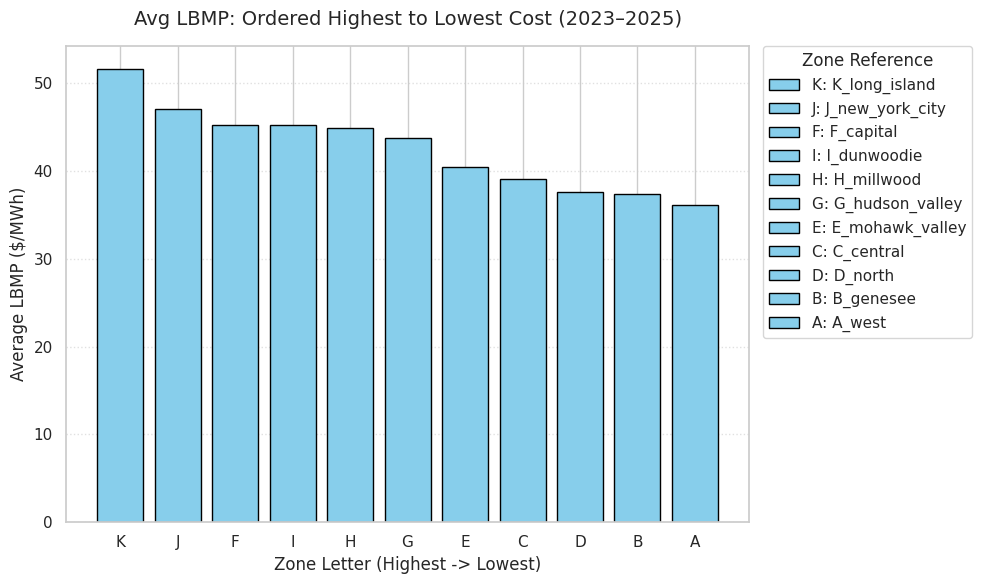

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Compute average LBMP per zone ordered from highest to lowest
avg_by_zone = congestion_dataframe.groupby("zone")["avg_lbmp"].mean().sort_values(ascending=False)
high_low_letters = [zone.split('_')[0] for zone in avg_by_zone.index]
high_low_legend = [f"{letter}: {name}" for letter, name in zip(high_low_letters, avg_by_zone.index)]

# Plotting a single chart
plt.figure(figsize=(10, 6))
bars = plt.bar(high_low_letters, avg_by_zone.values, color="skyblue", edgecolor="black")

# Set title and labels
plt.title("Avg LBMP: Ordered Highest to Lowest Cost (2023–2025)", fontsize=14, pad=15)
plt.xlabel("Zone Letter (Highest -> Lowest)", fontsize=12)
plt.ylabel("Average LBMP ($/MWh)", fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Add the mapping legend
plt.legend(bars, high_low_legend, title="Zone Reference", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

plt.tight_layout()
plt.show()

In [ ]:
#This graph shows the average lbmp cost per zone
#This graph doesn't show specific towns or boroughs in said zone.
#data doesn
#based on this data, we can't tell why certain zones have their average LBMP higher
#reasons as to ranking
#